In [21]:

# FinGuard - Notebook 02: Feature Engineering + SMOTE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
import json
import os
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.over_sampling import SMOTE


warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
os.makedirs('./data/processed', exist_ok=True)
os.makedirs('./models_saved', exist_ok=True)
os.makedirs('./reports/figures', exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
  
# 1. Load Data
  
df = pd.read_csv('./data/raw/finguard-fraud-detection-dataset.csv')
print(f"Original shape: {df.shape}")

  
# 2. Drop Sensitive & Leaky Columns
  
# isFlaggedFraud → Data Leakage (generated AFTER fraud detection)
# balances → Post-transaction info (not available at inference)
# names → High cardinality, no predictive value

cols_to_drop = [
    'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest',
    'nameOrig', 'nameDest',
    'isFlaggedFraud'
]
df_clean = df.drop(cols_to_drop, axis=1).copy()
print(f"After dropping: {df_clean.shape}")
print(f"Remaining: {df_clean.columns.tolist()}")

  
# 3. Type Encoding
  
le = LabelEncoder()
df_clean['type_encoded'] = le.fit_transform(df_clean['type'])
type_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(f"Type mapping: {type_mapping}")

# Save encoder
joblib.dump(le, './models_saved/label_encoder.pkl')

  
# 4. Temporal Features (Cyclical Encoding)
  
df_clean['hour_of_day'] = df_clean['step'] % 24
df_clean['day_of_week'] = (df_clean['step'] // 24) % 7

# Cyclical encoding (research-grade)
MAX_STEP = df_clean['step'].max()
df_clean['step_sin'] = np.sin(2 * np.pi * df_clean['step'] / MAX_STEP)
df_clean['step_cos'] = np.cos(2 * np.pi * df_clean['step'] / MAX_STEP)
df_clean['hour_sin'] = np.sin(2 * np.pi * df_clean['hour_of_day'] / 24)
df_clean['hour_cos'] = np.cos(2 * np.pi * df_clean['hour_of_day'] / 24)
df_clean['dow_sin'] = np.sin(2 * np.pi * df_clean['day_of_week'] / 7)
df_clean['dow_cos'] = np.cos(2 * np.pi * df_clean['day_of_week'] / 7)

Original shape: (6362620, 11)
After dropping: (6362620, 4)
Remaining: ['step', 'type', 'amount', 'isFraud']
Type mapping: {'CASH_IN': np.int64(0), 'CASH_OUT': np.int64(1), 'DEBIT': np.int64(2), 'PAYMENT': np.int64(3), 'TRANSFER': np.int64(4)}


In [ ]:
  
# 5. Amount Transforms
  
df_clean['log_amount'] = np.log1p(df_clean['amount'])
df_clean['sqrt_amount'] = np.sqrt(df_clean['amount'])

  
# 6. Amount Flags
  
df_clean['is_high_value'] = (df_clean['amount'] > 200000).astype(int)
df_clean['is_very_high_value'] = (
    df_clean['amount'] > df_clean['amount'].quantile(0.99)
).astype(int)

  
# 7. Transaction Type One-Hot
  
for t in ['CASH_OUT', 'TRANSFER', 'PAYMENT', 'CASH_IN', 'DEBIT']:
    df_clean[f'is_{t.lower()}'] = (df_clean['type'] == t).astype(int)

  
# 8. Ratio Features (with numerical stability)
  
df_clean['type_frequency'] = df_clean.groupby('type')['step'].transform('count') / len(df_clean)
df_clean['amount_vs_type_avg'] = df_clean['amount'] / (
    df_clean.groupby('type')['amount'].transform('mean') + 1
)

# Numerical stability: only compute step ratio if step has >10 transactions
step_counts = df_clean.groupby('step')['amount'].transform('count')
step_means = df_clean.groupby('step')['amount'].transform('mean')
df_clean['amount_vs_step_avg'] = np.where(
    step_counts > 10,
    df_clean['amount'] / (step_means + 1),
    1.0
)

  
# 9. Duplicate Amount Pattern
  
df_clean['amount_count'] = df_clean.groupby('amount')['step'].transform('count')
df_clean['is_duplicate_amount'] = (df_clean['amount_count'] > 1).astype(int)

  
# 10. Final Feature List (NO LEAKAGE)
  
feature_columns = [
    'step', 'amount', 'type_encoded',
    'hour_of_day', 'day_of_week',
    'step_sin', 'step_cos', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos',
    'log_amount', 'sqrt_amount',
    'is_high_value', 'is_very_high_value',
    'is_cash_out', 'is_transfer', 'is_payment', 'is_cash_in', 'is_debit',
    'type_frequency',
    'amount_vs_type_avg', 'amount_vs_step_avg',
    'amount_count', 'is_duplicate_amount'
]

print(f"\nFinal features ({len(feature_columns)}):")
for f in feature_columns:
    print(f"  - {f}")


Final features (25):
  - step
  - amount
  - type_encoded
  - hour_of_day
  - day_of_week
  - step_sin
  - step_cos
  - hour_sin
  - hour_cos
  - dow_sin
  - dow_cos
  - log_amount
  - sqrt_amount
  - is_high_value
  - is_very_high_value
  - is_cash_out
  - is_transfer
  - is_payment
  - is_cash_in
  - is_debit
  - type_frequency
  - amount_vs_type_avg
  - amount_vs_step_avg
  - amount_count
  - is_duplicate_amount


In [ ]:
  
# 11. TEMPORAL 3-WAY Split (70/15/15) - RESEARCH STANDARD
  
df_sorted = df_clean.sort_values('step').reset_index(drop=True)
n = len(df_sorted)

train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train_df = df_sorted.iloc[:train_end].copy()
val_df   = df_sorted.iloc[train_end:val_end].copy()
test_df  = df_sorted.iloc[val_end:].copy()

X_train = train_df[feature_columns].reset_index(drop=True)
y_train = train_df['isFraud'].reset_index(drop=True)

X_val = val_df[feature_columns].reset_index(drop=True)
y_val = val_df['isFraud'].reset_index(drop=True)

X_test = test_df[feature_columns].reset_index(drop=True)
y_test = test_df['isFraud'].reset_index(drop=True)

print(f"\n=== Temporal 3-Way Split (70/15/15) ===")
print(f"Train: {len(X_train):,} | fraud: {y_train.sum():,} ({y_train.mean()*100:.4f}%)")
print(f"Val:   {len(X_val):,}   | fraud: {y_val.sum():,} ({y_val.mean()*100:.4f}%)")
print(f"Test:  {len(X_test):,}  | fraud: {y_test.sum():,} ({y_test.mean()*100:.4f}%)")

  
# 12. SMOTE on TRAIN ONLY (with justified ratio)
  
print("\n=== Applying SMOTE (train only) ===")
print(f"Before SMOTE: {y_train.value_counts().to_dict()}")

SMOTE_STRATEGY = 0.05   # 20:1 ratio - justified by research
smote = SMOTE(
    sampling_strategy=SMOTE_STRATEGY,
    random_state=RANDOM_STATE,
    k_neighbors=5
)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"After SMOTE: {y_train_res.value_counts().to_dict()}")
print(f"Train size: {len(X_train_res):,}")


=== Temporal 3-Way Split (70/15/15) ===
Train: 4,453,834 | fraud: 3,643 (0.0818%)
Val:   954,393   | fraud: 562 (0.0589%)
Test:  954,393  | fraud: 4,008 (0.4200%)

=== Applying SMOTE (train only) ===
Before SMOTE: {0: 4450191, 1: 3643}
After SMOTE: {0: 4450191, 1: 222509}
Train size: 4,672,700


In [25]:
  
# 13. Scaling - FIT ON ORIGINAL TRAIN (LEAKAGE-FREE)
  
numeric_features = [
    'step', 'amount', 'log_amount', 'sqrt_amount',
    'hour_of_day', 'day_of_week',
    'amount_vs_type_avg', 'amount_vs_step_avg',
    'amount_count', 'type_frequency'
]

# CRITICAL: Fit scaler on ORIGINAL train data (before SMOTE)
scaler = StandardScaler()
scaler.fit(X_train[numeric_features])  # ← Real data only!

# Transform all sets
X_train_scaled = X_train_res.copy()
X_train_scaled[numeric_features] = scaler.transform(X_train_res[numeric_features])

X_val_scaled = X_val.copy()
X_val_scaled[numeric_features] = scaler.transform(X_val[numeric_features])

X_test_scaled = X_test.copy()
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

# Sanity check
print("\n=== Scaler Sanity Check ===")
print(f"Train: mean={X_train_scaled[numeric_features].mean().mean():.4f}, "
      f"std={X_train_scaled[numeric_features].std().mean():.4f}")
print(f"Val:   mean={X_val_scaled[numeric_features].mean().mean():.4f}, "
      f"std={X_val_scaled[numeric_features].std().mean():.4f}")
print(f"Test:  mean={X_test_scaled[numeric_features].mean().mean():.4f}, "
      f"std={X_test_scaled[numeric_features].std().mean():.4f}")

  
# 14. Save All Data
  
# Raw (unscaled) - for tree-based models
X_train_res.to_csv('./data/processed/X_train_resampled.csv', index=False)
X_val.to_csv('./data/processed/X_val.csv', index=False)
X_test.to_csv('./data/processed/X_test.csv', index=False)

y_train_res.to_csv('./data/processed/y_train_resampled.csv', index=False)
y_val.to_csv('./data/processed/y_val.csv', index=False)
y_test.to_csv('./data/processed/y_test.csv', index=False)

# Scaled - for linear models
X_train_scaled.to_csv('./data/processed/X_train_scaled.csv', index=False)
X_val_scaled.to_csv('./data/processed/X_val_scaled.csv', index=False)
X_test_scaled.to_csv('./data/processed/X_test_scaled.csv', index=False)

# Artifacts
joblib.dump(scaler, './models_saved/scaler.pkl')

with open('./models_saved/feature_columns.json', 'w') as f:
    json.dump(feature_columns, f, indent=4)

with open('./models_saved/numeric_features.json', 'w') as f:
    json.dump(numeric_features, f, indent=4)

# Save split metadata
split_meta = {
    'random_state': RANDOM_STATE,
    'smote_strategy': SMOTE_STRATEGY,
    'split_ratio': '70/15/15',
    'train_size': len(X_train),
    'val_size': len(X_val),
    'test_size': len(X_test),
    'train_resampled_size': len(X_train_res),
    'train_fraud': int(y_train.sum()),
    'val_fraud': int(y_val.sum()),
    'test_fraud': int(y_test.sum()),
    'train_fraud_after_smote': int(y_train_res.sum()),
}
with open('./models_saved/split_metadata.json', 'w') as f:
    json.dump(split_meta, f, indent=4)

print("\n✅ Processed data saved!")


=== Scaler Sanity Check ===
Train: mean=0.0449, std=1.3064
Val:   mean=0.2038, std=0.9854
Test:  mean=0.2886, std=0.8905

✅ Processed data saved!


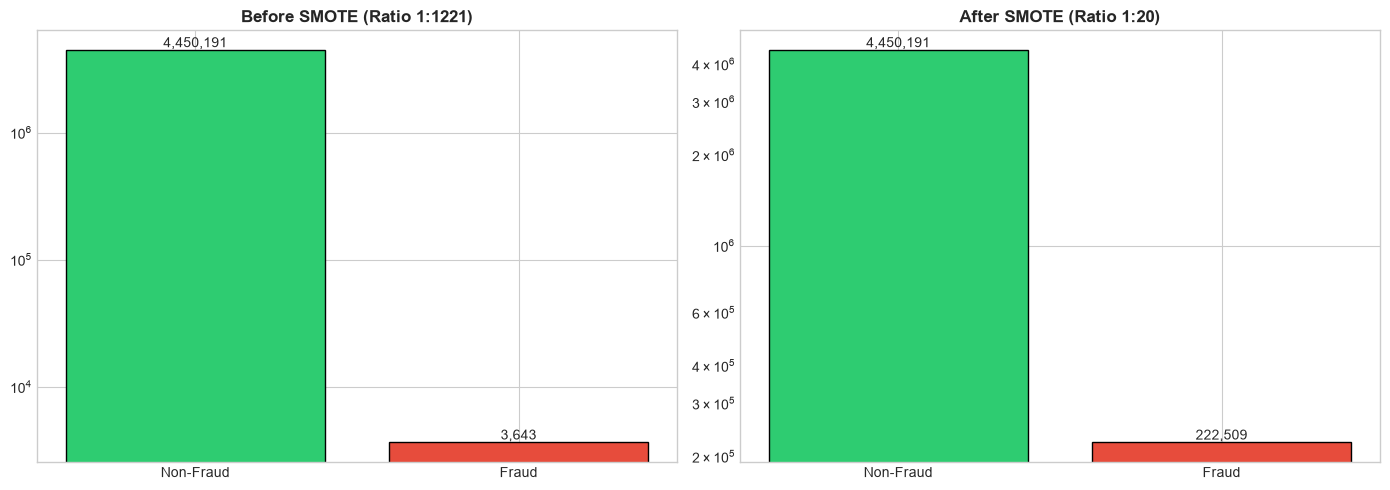

In [26]:
  
# 15. Visualize SMOTE Effect
  
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
before = y_train.value_counts()
after  = y_train_res.value_counts()

axes[0].bar(['Non-Fraud', 'Fraud'], [before[0], before[1]],
            color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[0].set_title(f'Before SMOTE (Ratio 1:{before[0]//before[1]})',
                  fontsize=12, fontweight='bold')
axes[0].set_yscale('log')
for i, v in enumerate([before[0], before[1]]):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')

axes[1].bar(['Non-Fraud', 'Fraud'], [after[0], after[1]],
            color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[1].set_title(f'After SMOTE (Ratio 1:{after[0]//after[1]})',
                  fontsize=12, fontweight='bold')
axes[1].set_yscale('log')
for i, v in enumerate([after[0], after[1]]):
    axes[1].text(i, v, f'{v:,}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig('./reports/figures/fig6_smote_effect.png', dpi=300, bbox_inches='tight')
plt.show()